In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT))
from qsegment import metrics as mt, scenario as sc

R = {name: json.loads((ROOT / "results" / f"{name}.json").read_text())
     for name in ("01_verify", "02_baselines", "02b_gurobi", "03_qaoa_repeats", "04_noisy_sim", "05_backend_choice", "06_hardware_probe", "07_hardware_final")}
Q3, H4, H5, H6, H7 = R["03_qaoa_repeats"], R["04_noisy_sim"], R["05_backend_choice"], R["06_hardware_probe"], R["07_hardware_final"]

plt.rcParams.update({"font.size": 11, "axes.spines.top": False, "axes.spines.right": False,
                     "figure.facecolor": "white", "axes.facecolor": "white", "figure.dpi": 110})
BLUE, GREEN, RED, PURPLE, ORANGE, GRAY = "#1f77b4", "#2ca02c", "#d62728", "#9467bd", "#f28e2b", "#6b7280"
LEGEND = dict(frameon=True, facecolor="white", edgecolor="#d1d5db", framealpha=0.95, fontsize=9)
RANDOM = 100 / 128
se = lambda x: float(np.std(x, ddof=1) / np.sqrt(len(x)))
JOBS = {(j["variant"], j["p"]): j for j in H7["jobs"]}
hw = lambda job, mode, key: np.array([r[mode][key] for r in job["results"]])

## T1 Scenario: traffic and risk per pair

In [2]:
rows = [(sc.SYSTEMS[i], sc.SYSTEMS[j], sc.traffic(i, j), sc.risk(i, j), sc.net_weight(i, j)) for i, j in sc.PAIRS]
pd.DataFrame(rows, columns=["System A", "System B", "Traffic", "Risk", "Net weight (risk - traffic)"]).style.hide(axis="index")

System A,System B,Traffic,Risk,Net weight (risk - traffic)
nurse,email,3,0,-3
nurse,pacs,0,2,2
nurse,pharm,2,0,-2
nurse,ehr,6,7,1
nurse,billing,0,3,3
mri,pacs,6,0,-6
mri,pharm,0,2,2
mri,ehr,0,5,5
mri,billing,0,4,4
portal,email,2,0,-2


## T2 Problem and formulation size

In [3]:
rows = []
free_pairs = [(i, j) for i, j in sc.PAIRS if i != sc.FIXED]
nurse_pairs = [(i, j) for i, j in sc.PAIRS if i == sc.FIXED and sc.net_weight(i, j) != 0]
for K in (2, 3):
    costs = np.array(sc.cost_table(K))
    rows.append((f"{K} zones", 7 if K == 2 else 21, f"{K ** 7} ({2 ** 21:,} bitstrings)" if K == 3 else "128",
                 f"{(1 if K == 2 else 3) * len(free_pairs)} two-qubit + {len(nurse_pairs)} single-qubit terms",
                 f"{costs.min():.0f} ({int((costs == costs.min()).sum())} partition{'s' if (costs == costs.min()).sum() > 1 else ''})",
                 f"{costs.mean():.1f}", f"{costs.max():.0f}"))
pd.DataFrame(rows, columns=["Problem", "Qubits", "Valid partitions", "Hamiltonian terms", "Optimal cost", "Mean cost", "Worst cost"]).style.hide(axis="index")

Problem,Qubits,Valid partitions,Hamiltonian terms,Optimal cost,Mean cost,Worst cost
2 zones,7,128,13 two-qubit + 5 single-qubit terms,26 (1 partition),43.5,60
3 zones,21,"2187 (2,097,152 bitstrings)",39 two-qubit + 5 single-qubit terms,25 (2 partitions),43.0,60


## P1 The best split

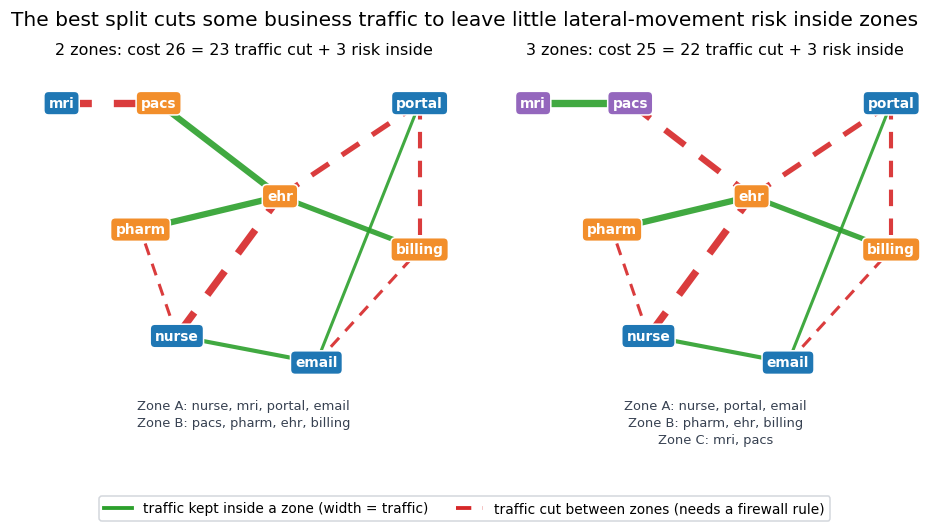

In [4]:
from matplotlib.lines import Line2D

POS = {"ehr": (0, 0), "pacs": (-2, 1.4), "mri": (-3.6, 1.4), "pharm": (-2.3, -0.5), "nurse": (-1.7, -2.1),
       "email": (0.6, -2.5), "billing": (2.3, -0.8), "portal": (2.3, 1.4)}
ZONE_COLORS = [BLUE, ORANGE, PURPLE]
fig, axes = plt.subplots(1, 2, figsize=(10.8, 4.8))
for ax, K in zip(axes, (2, 3)):
    costs = sc.cost_table(K)
    best = min(costs)
    z = sc.decode(costs.index(best), K)
    traffic_cut = sum(sc.traffic(i, j) for i, j in sc.PAIRS if z[i] != z[j])
    risk_inside = sum(sc.risk(i, j) for i, j in sc.PAIRS if z[i] == z[j])
    for i, j in sc.PAIRS:
        t = sc.traffic(i, j)
        if t:
            (x1, y1), (x2, y2) = POS[sc.SYSTEMS[i]], POS[sc.SYSTEMS[j]]
            kept = z[i] == z[j]
            ax.plot([x1, x2], [y1, y2], color=GREEN if kept else RED, ls="-" if kept else (0, (4, 3)), lw=0.7 * t + 0.6, alpha=0.9, zorder=1)
    for i, name in enumerate(sc.SYSTEMS):
        ax.text(*POS[name], name, ha="center", va="center", color="white", fontsize=9, fontweight="bold", zorder=3,
                bbox=dict(boxstyle="round,pad=0.35", fc=ZONE_COLORS[z[i]], ec="white"))
    ax.set_xlim(-4.3, 3.1)
    ax.set_ylim(-3.0, 2.0)
    ax.axis("off")
    zones = "\n".join(f"Zone {chr(65 + k)}: {', '.join(n for n, zz in zip(sc.SYSTEMS, z) if zz == k)}" for k in range(K))
    ax.set_title(f"{K} zones: cost {best:.0f} = {traffic_cut} traffic cut + {risk_inside} risk inside", fontsize=10.5)
    ax.text(0.5, -0.01, zones, transform=ax.transAxes, ha="center", va="top", fontsize=8.5, color="#374151", linespacing=1.4)
fig.suptitle("The best split cuts some business traffic to leave little lateral-movement risk inside zones")
fig.legend(handles=[Line2D([0], [0], color=GREEN, lw=2.5, label="traffic kept inside a zone (width = traffic)"),
                    Line2D([0], [0], color=RED, lw=2.5, ls=(0, (4, 3)), label="traffic cut between zones (needs a firewall rule)")],
           loc="lower center", ncol=2, bbox_to_anchor=(0.5, 0.0), **LEGEND)
fig.subplots_adjust(bottom=0.25, top=0.88, wspace=0.05)
plt.show()

## P2 Cost of every partition

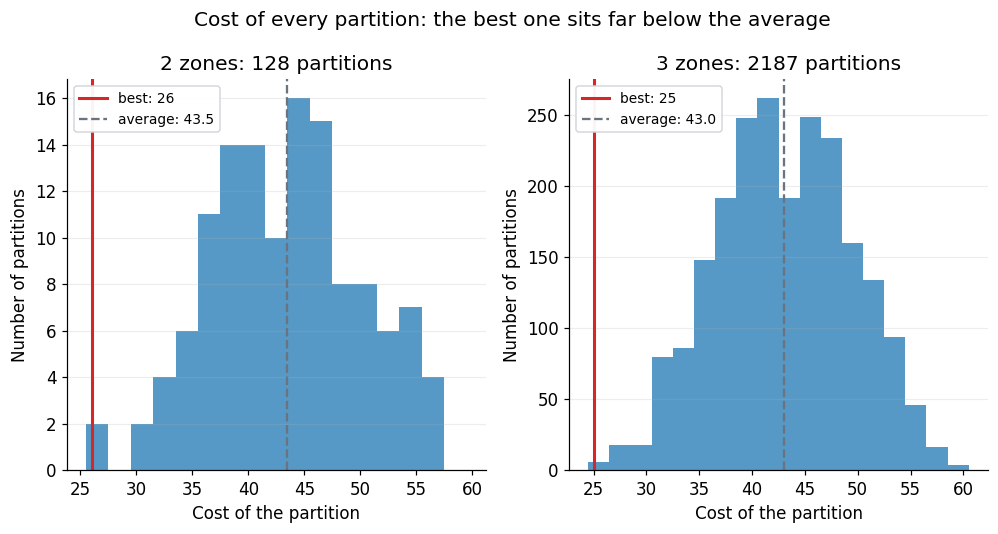

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(10.8, 4.8))
for ax, K in zip(axes, (2, 3)):
    costs = np.array(sc.cost_table(K))
    ax.hist(costs, bins=np.arange(costs.min() - 0.5, costs.max() + 1.5, 2), color=BLUE, alpha=0.75)
    ax.axvline(costs.min(), color=RED, lw=2, label=f"best: {costs.min():.0f}")
    ax.axvline(costs.mean(), color=GRAY, ls="--", lw=1.5, label=f"average: {costs.mean():.1f}")
    ax.set(xlabel="Cost of the partition", ylabel="Number of partitions", title=f"{K} zones: {K ** 7} partitions")
    ax.yaxis.grid(True, alpha=0.22)
    ax.legend(loc="upper left", **LEGEND)
fig.suptitle("Cost of every partition: the best one sits far below the average")
fig.subplots_adjust(top=0.85)
plt.show()

## P3 The circuit

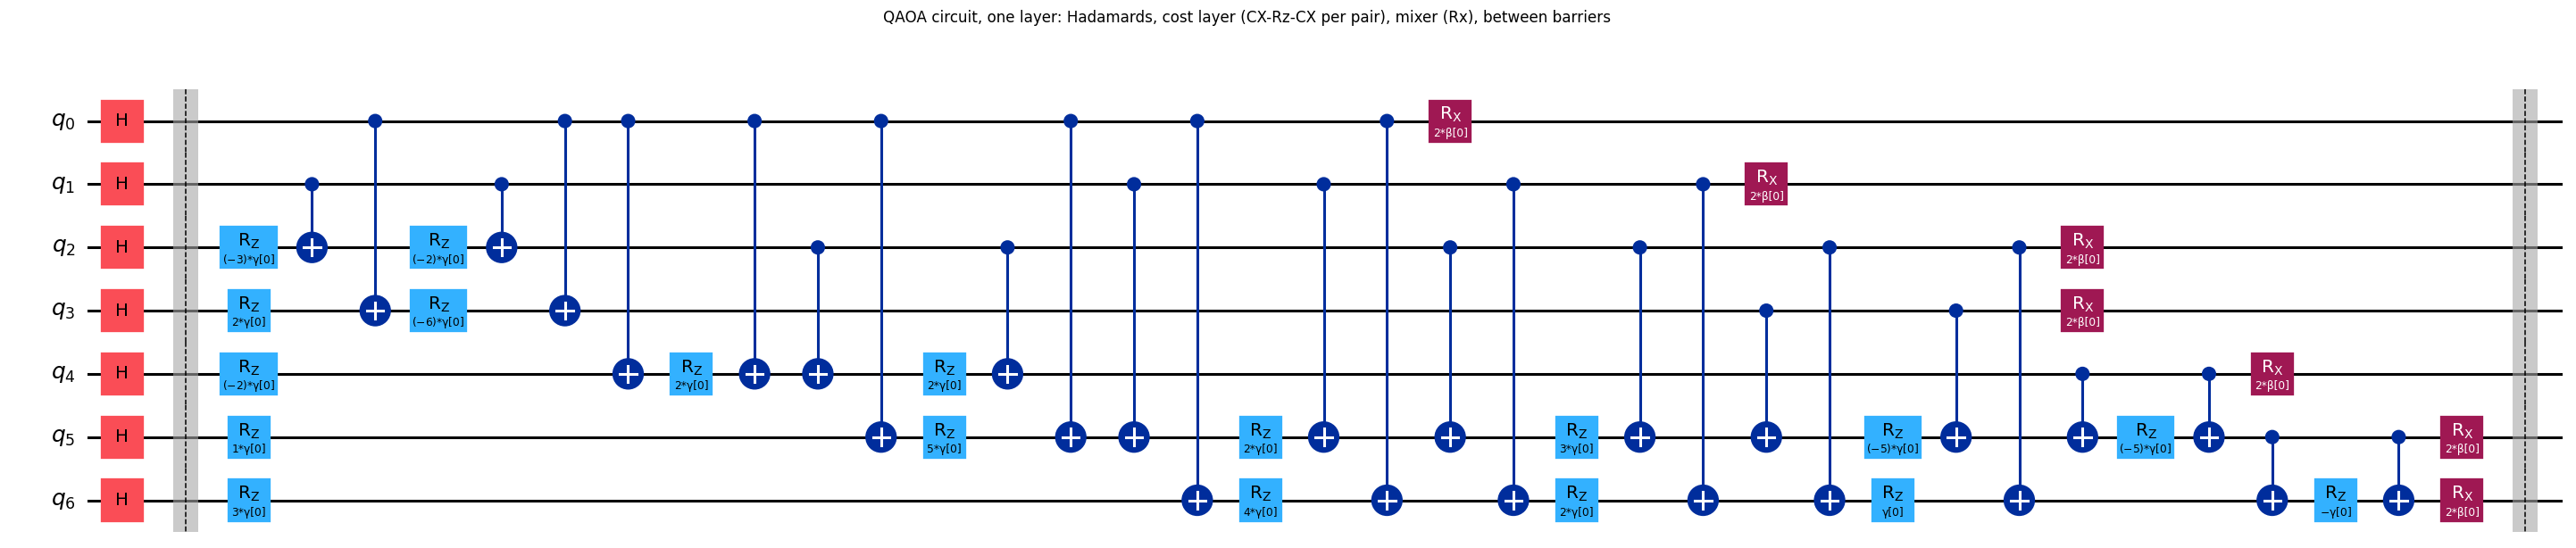

In [6]:
from qiskit import QuantumCircuit, transpile
from qiskit.circuit.library import QAOAAnsatz

from qsegment import formulation as fm

H, _ = fm.ising_2zone()
init = QuantumCircuit(H.num_qubits)
init.h(range(H.num_qubits))
init.barrier()
ansatz = QAOAAnsatz(cost_operator=H, reps=1, initial_state=init)
ansatz.insert_barriers = True
logical = transpile(ansatz, basis_gates=["h", "cx", "rz", "rx"], optimization_level=0)
fig = logical.draw("mpl", fold=40)
fig.suptitle("QAOA circuit, one layer: Hadamards, cost layer (CX-Rz-CX per pair), mixer (Rx), between barriers", fontsize=11)
fig

## P4 Where QAOA puts the probability (noiseless)

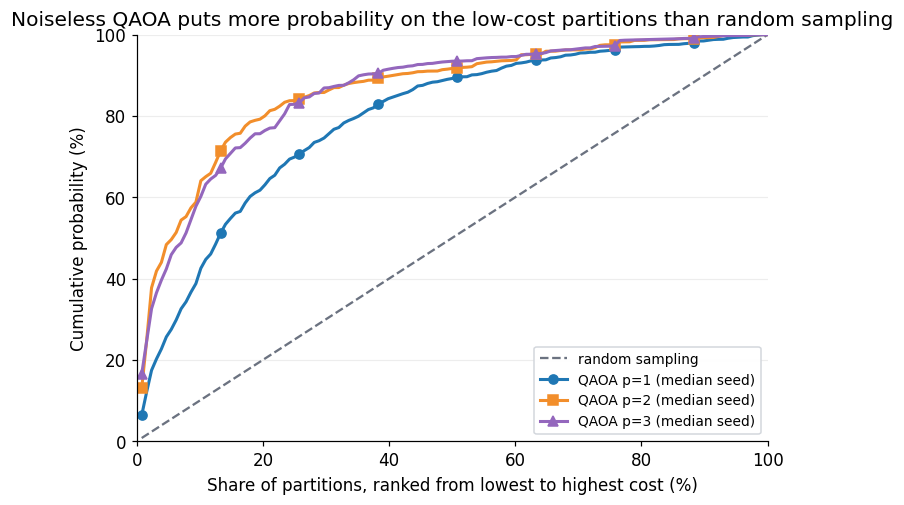

In [7]:
from qsegment import qaoa

costs = np.array(sc.cost_table(2))
order = np.argsort(costs, kind="stable")
fig, ax = plt.subplots(figsize=(7.4, 4.8))
x = np.arange(1, 129) / 128 * 100
ax.plot(x, x, color=GRAY, ls="--", lw=1.5, label="random sampling")
for p, color, marker in zip((1, 2, 3), (BLUE, ORANGE, PURPLE), ("o", "s", "^")):
    run = sorted(Q3["runs"][str(p)], key=lambda r: r["ideal"]["p_best"])[10]
    cum = 100 * np.cumsum(qaoa.ideal_probs(p, run["gammas"], run["betas"])[order])
    ax.plot(x, cum, color=color, marker=marker, markevery=16, ms=6, lw=2, label=f"QAOA p={p} (median seed)")
ax.set(xlabel="Share of partitions, ranked from lowest to highest cost (%)", ylabel="Cumulative probability (%)", xlim=(0, 100), ylim=(0, 100))
ax.yaxis.grid(True, alpha=0.22)
ax.legend(loc="lower right", **LEGEND)
ax.set_title("Noiseless QAOA puts more probability on the low-cost partitions than random sampling")
plt.show()

## P5 QAOA against random guessing

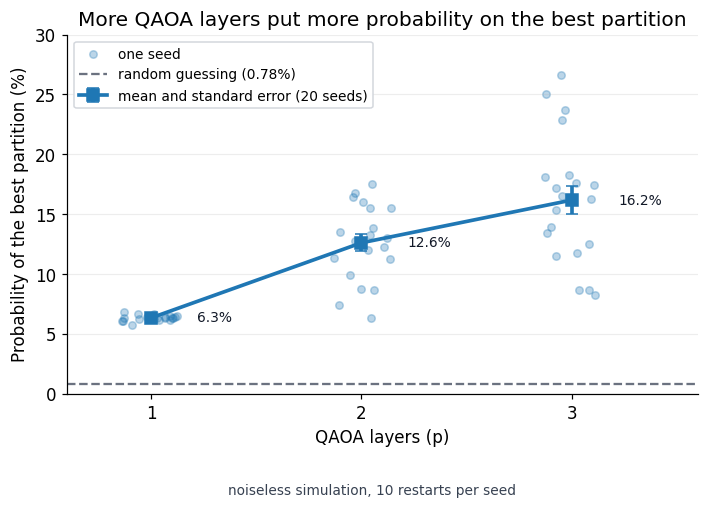

In [8]:
ps = [1, 2, 3]
rng = np.random.default_rng(0)
fig, ax = plt.subplots(figsize=(7.4, 4.8))
means, errs = [], []
for p in ps:
    vals = [100 * r["ideal"]["p_best"] for r in Q3["runs"][str(p)]]
    means.append(np.mean(vals))
    errs.append(se(vals))
    ax.scatter(p + rng.uniform(-0.14, 0.14, len(vals)), vals, s=24, color=BLUE, alpha=0.3, marker="o", label="one seed" if p == 1 else None)
ax.errorbar(ps, means, yerr=errs, color=BLUE, marker="s", ms=8, lw=2.4, capsize=4, label="mean and standard error (20 seeds)")
ax.axhline(RANDOM, color=GRAY, ls="--", lw=1.5, label="random guessing (0.78%)")
for p, m in zip(ps, means):
    ax.text(p + 0.22, m, f"{m:.1f}%", va="center", fontsize=9, color="#111827")
ax.set(xticks=ps, xlabel="QAOA layers (p)", ylabel="Probability of the best partition (%)", ylim=(0, 30), xlim=(0.6, 3.6))
ax.yaxis.grid(True, alpha=0.22)
ax.legend(loc="upper left", **LEGEND)
ax.set_title("More QAOA layers put more probability on the best partition")
fig.text(0.5, 0.01, "noiseless simulation, 10 restarts per seed", ha="center", fontsize=9, color="#374151")
fig.subplots_adjust(bottom=0.2)
plt.show()

## T3 Classical baselines

In [9]:
b, g = R["02_baselines"], R["02b_gurobi"]
rows = [("Brute force (all 128)", "exact", 128, f"{b['brute_force']['seconds']['median'] * 1e3:.2f} ms total")]
for name, label in (("random", "Random sampling"), ("greedy", "Greedy search"), ("annealing", "Simulated annealing")):
    s = b["summary"][name]
    rows.append((label, f"{s['success_rate']:.0%} of 20 seeds", f"{s['evals_to_first_hit']['median']:.0f}", f"{s['seconds_to_first_hit']['median'] * 1e3:.2f} ms to first hit"))
rows.append(("Gurobi (exact solver)", f"optimal, all {g['summary']['solve_seconds']['n']} runs", "1 solve", f"{g['summary']['solve_seconds']['median'] * 1e3:.2f} ms"))
pd.DataFrame(rows, columns=["Method", "Found the best partition", "Median evaluations to first hit", "Time"]).style.hide(axis="index")

Method,Found the best partition,Median evaluations to first hit,Time
Brute force (all 128),exact,128,0.49 ms total
Random sampling,100% of 20 seeds,102,0.44 ms to first hit
Greedy search,100% of 20 seeds,18,0.08 ms to first hit
Simulated annealing,100% of 20 seeds,82,0.47 ms to first hit
Gurobi (exact solver),"optimal, all 20 runs",1 solve,0.49 ms


## T4 Noiseless QAOA by layers

In [10]:
rows = []
for p in ("1", "2", "3"):
    s = Q3["summary"][p]
    rows.append((int(p), f"{100 * s['p_best']['mean']:.1f} ± {100 * s['p_best']['std']:.1f}", f"{100 * s['p_best']['min']:.1f} - {100 * s['p_best']['max']:.1f}",
                 f"{s['avg_cost']['mean']:.1f}", f"{s['approx_ratio']['mean']:.3f}", f"{s['shots_to_hit']['median']:.1f}",
                 f"{s['tuning_shots']['mean']:,.0f}", f"{s['tuning_seconds']['median']:.1f}"))
pd.DataFrame(rows, columns=["p", "Best-partition probability (%, mean ± sd)", "Range (%)", "Average cost", "Approximation ratio", "Shots to hit (median)", "Training shots (mean)", "Training time (s, median)"]).style.hide(axis="index")

p,"Best-partition probability (%, mean ± sd)",Range (%),Average cost,Approximation ratio,Shots to hit (median),Training shots (mean),"Training time (s, median)"
1,6.3 ± 0.2,5.7 - 6.8,36.3,0.698,15.8,"256,666",0.4
2,12.6 ± 3.2,6.3 - 17.5,34.1,0.763,7.8,"347,802",0.7
3,16.2 ± 5.4,8.2 - 26.6,33.3,0.785,6.1,"435,354",1.2


## P6 Time to find the best partition

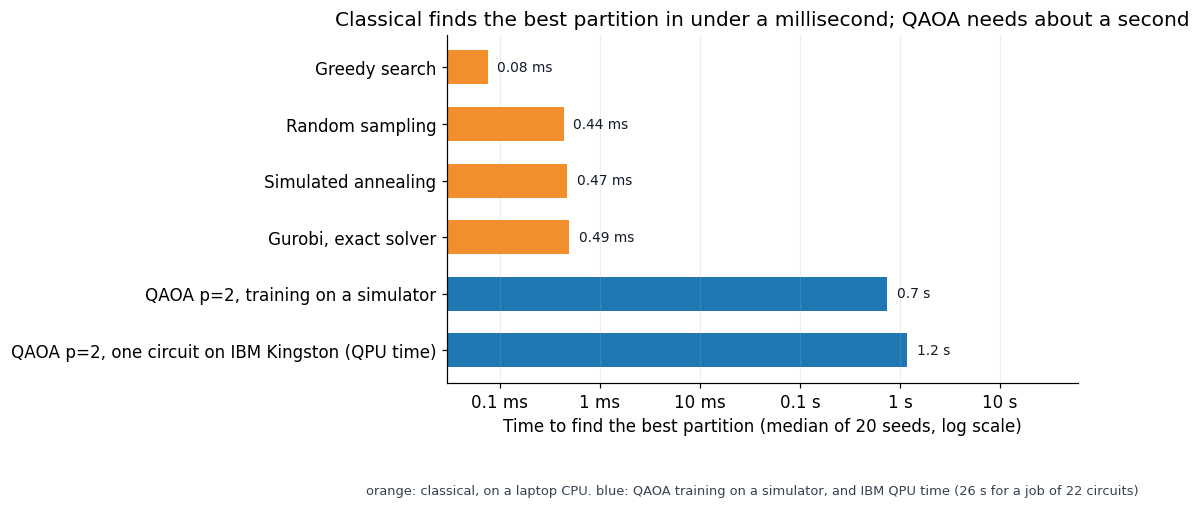

In [11]:
from matplotlib.ticker import FixedLocator, FuncFormatter, NullLocator

base = R["02_baselines"]["summary"]
classical = [("Greedy search", base["greedy"]["seconds_to_first_hit"]["median"]),
             ("Simulated annealing", base["annealing"]["seconds_to_first_hit"]["median"]),
             ("Random sampling", base["random"]["seconds_to_first_hit"]["median"]),
             ("Gurobi, exact solver", R["02b_gurobi"]["summary"]["solve_seconds"]["median"])]
job = JOBS[("main", 2)]
qaoa = [("QAOA p=2, training on a simulator", Q3["summary"]["2"]["tuning_seconds"]["median"]),
        ("QAOA p=2, one circuit on IBM Kingston (QPU time)", job["usage_seconds"] / (job["sets"] + 2))]
rows = sorted(classical, key=lambda r: r[1]) + qaoa
colors = [ORANGE] * len(classical) + [BLUE] * len(qaoa)
fmt = lambda s: f"{s * 1e3:.2f} ms" if s < 0.1 else f"{s:.1f} s"
fig, ax = plt.subplots(figsize=(7.4, 4.8))
ax.barh([r[0] for r in rows], [r[1] for r in rows], color=colors, height=0.6)
ax.set_xscale("log")
ax.set_xlim(3e-5, 60)
ax.xaxis.set_major_locator(FixedLocator([1e-4, 1e-3, 1e-2, 1e-1, 1, 10]))
ax.set_xticklabels(["0.1 ms", "1 ms", "10 ms", "0.1 s", "1 s", "10 s"])
ax.xaxis.set_minor_locator(NullLocator())
for y, (_, v) in enumerate(rows):
    ax.text(v * 1.25, y, fmt(v), va="center", fontsize=9, color="#111827")
ax.set_xlabel("Time to find the best partition (median of 20 seeds, log scale)")
ax.xaxis.grid(True, alpha=0.22)
ax.invert_yaxis()
ax.set_title("Classical finds the best partition in under a millisecond; QAOA needs about a second")
fig.text(0.5, 0.01, "orange: classical, on a laptop CPU. blue: QAOA training on a simulator, and IBM QPU time (26 s for a job of 22 circuits)", ha="center", fontsize=8.5, color="#374151")
fig.subplots_adjust(bottom=0.22)
plt.show()

## P6b Evaluations or shots against classical search (backup)

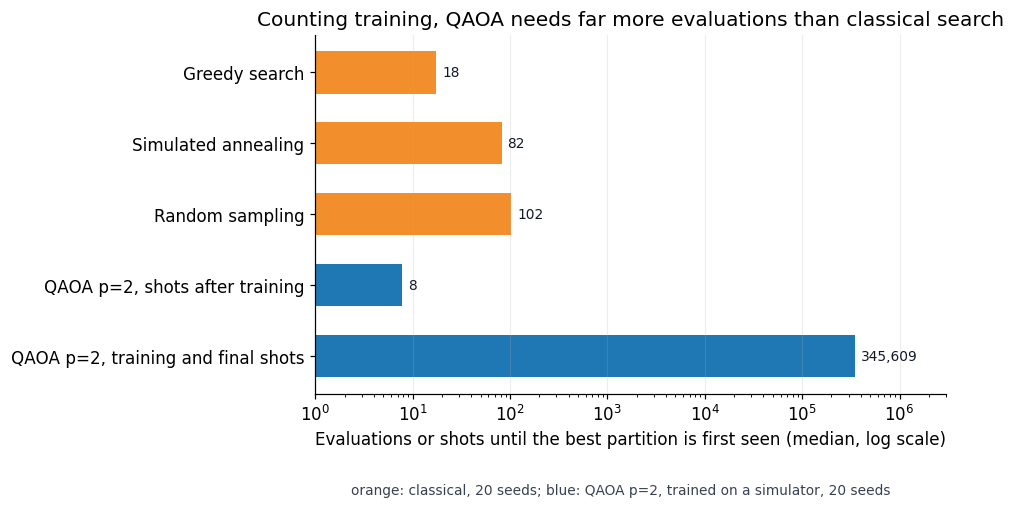

In [12]:
base = R["02_baselines"]["summary"]
q2 = Q3["summary"]["2"]
rows = [("Greedy search", base["greedy"]["evals_to_first_hit"]["median"], ORANGE),
        ("Simulated annealing", base["annealing"]["evals_to_first_hit"]["median"], ORANGE),
        ("Random sampling", base["random"]["evals_to_first_hit"]["median"], ORANGE),
        ("QAOA p=2, shots after training", q2["shots_to_hit"]["median"], BLUE),
        ("QAOA p=2, training and final shots", q2["total_shots_to_hit"]["median"], BLUE)]
rows.sort(key=lambda r: (r[2] == BLUE, r[1]))
fig, ax = plt.subplots(figsize=(7.4, 4.8))
ax.barh([r[0] for r in rows], [r[1] for r in rows], color=[r[2] for r in rows], height=0.6)
ax.set_xscale("log")
ax.set_xlim(1, 3e6)
for y, (_, v, _) in enumerate(rows):
    ax.text(v * 1.15, y, f"{v:,.0f}", va="center", fontsize=9, color="#111827")
ax.set(xlabel="Evaluations or shots until the best partition is first seen (median, log scale)")
ax.xaxis.grid(True, alpha=0.22)
ax.invert_yaxis()
ax.set_title("Counting training, QAOA needs far more evaluations than classical search")
fig.text(0.5, 0.01, "orange: classical, 20 seeds; blue: QAOA p=2, trained on a simulator, 20 seeds", ha="center", fontsize=9, color="#374151")
fig.subplots_adjust(bottom=0.2)
plt.show()

## T10 End-to-end effort

In [13]:
b, q2 = R["02_baselines"]["summary"], Q3["summary"]["2"]
rows = [("Greedy search", f"{b['greedy']['evals_to_first_hit']['median']:.0f} evaluations", "none", f"{b['greedy']['seconds_to_first_hit']['median'] * 1e3:.2f} ms"),
        ("Simulated annealing", f"{b['annealing']['evals_to_first_hit']['median']:.0f} evaluations", "none", f"{b['annealing']['seconds_to_first_hit']['median'] * 1e3:.2f} ms"),
        ("Random sampling", f"{b['random']['evals_to_first_hit']['median']:.0f} evaluations", "none", f"{b['random']['seconds_to_first_hit']['median'] * 1e3:.2f} ms"),
        ("QAOA p=2, simulated", f"{q2['shots_to_hit']['median']:.1f} shots after training", f"{q2['tuning_shots']['mean']:,.0f} simulated shots", f"{q2['tuning_seconds']['median']:.1f} s training"),
        ("QAOA p=2, IBM Kingston", "4096 shots per circuit", "trained on a simulator", f"{JOBS[('main', 2)]['usage_seconds']} QPU s for 22 circuits")]
pd.DataFrame(rows, columns=["Method", "Effort to see the best partition", "Training effort", "Time"]).style.hide(axis="index")

Method,Effort to see the best partition,Training effort,Time
Greedy search,18 evaluations,none,0.08 ms
Simulated annealing,82 evaluations,none,0.47 ms
Random sampling,102 evaluations,none,0.44 ms
"QAOA p=2, simulated",7.8 shots after training,"347,802 simulated shots",0.7 s training
"QAOA p=2, IBM Kingston",4096 shots per circuit,trained on a simulator,26 QPU s for 22 circuits


## P7 Transpiler levels

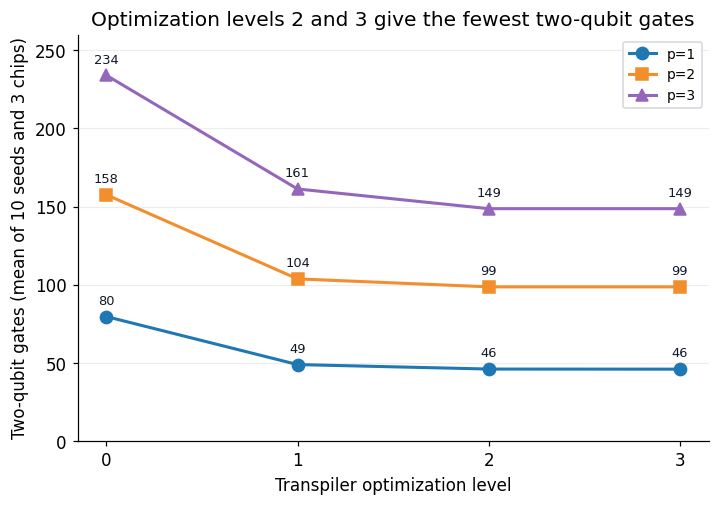

In [14]:
levels = (0, 1, 2, 3)
fig, ax = plt.subplots(figsize=(7.4, 4.8))
for p, color, marker in zip((1, 2, 3), (BLUE, ORANGE, PURPLE), ("o", "s", "^")):
    means = [np.mean([r["transpile_by_level"][str(l)]["two_qubit_gates"]["mean"] for r in H4["results"] if r["p"] == p]) for l in levels]
    ax.plot(levels, means, color=color, marker=marker, ms=8, lw=2, label=f"p={p}")
    for l, m in zip(levels, means):
        ax.annotate(f"{m:.0f}", (l, m), textcoords="offset points", xytext=(0, 8), ha="center", fontsize=8.5, color="#111827")
ax.set(xticks=levels, xlabel="Transpiler optimization level", ylabel="Two-qubit gates (mean of 10 seeds and 3 chips)", ylim=(0, 260))
ax.yaxis.grid(True, alpha=0.22)
ax.legend(loc="upper right", **LEGEND)
ax.set_title("Optimization levels 2 and 3 give the fewest two-qubit gates")
plt.show()

## T5 Transpiler comparison

In [15]:
rows = []
for r in H4["results"]:
    lv = r["transpile_by_level"]
    c = r["chosen_transpile"]
    rows.append((r["backend"], r["p"], *(f"{lv[str(l)]['two_qubit_gates']['mean']:.0f}" for l in range(4)), f"level {c['level']}, seed {c['seed']}", c["two_qubit_gates"], c["depth"]))
pd.DataFrame(rows, columns=["Fake backend", "p", "Level 0", "Level 1", "Level 2", "Level 3", "Chosen", "Two-qubit gates", "Depth"]).style.hide(axis="index")

Fake backend,p,Level 0,Level 1,Level 2,Level 3,Chosen,Two-qubit gates,Depth
sherbrooke,1,80,49,46,46,"level 2, seed 9",42,134
sherbrooke,2,158,105,98,98,"level 2, seed 2",98,239
sherbrooke,3,234,165,148,148,"level 2, seed 9",141,401
fez,1,80,49,46,46,"level 2, seed 5",42,106
fez,2,158,103,99,99,"level 2, seed 3",98,210
fez,3,234,160,149,149,"level 2, seed 9",141,338
marrakesh,1,80,49,46,46,"level 2, seed 5",42,106
marrakesh,2,158,103,99,99,"level 2, seed 3",98,209
marrakesh,3,234,160,149,149,"level 2, seed 9",141,328


## P8 Fidelity on the fake backends

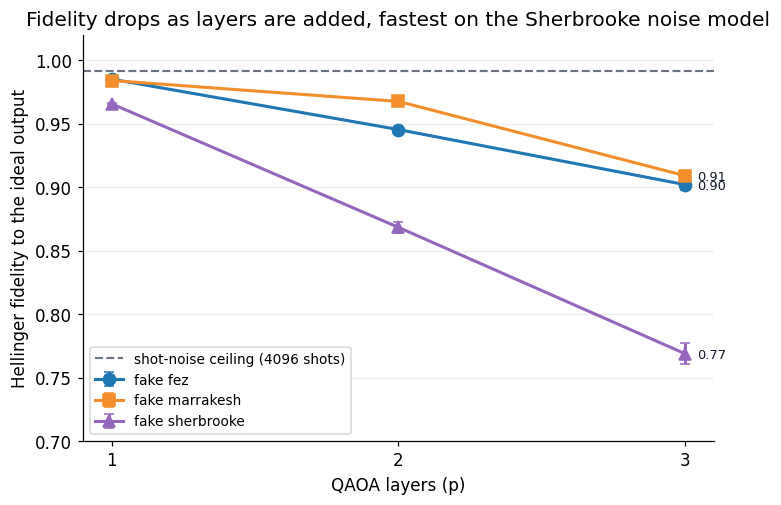

In [16]:
fig, ax = plt.subplots(figsize=(7.4, 4.8))
names = ["fez", "marrakesh", "sherbrooke"]
for name, color, marker in zip(names, (BLUE, ORANGE, PURPLE), ("o", "s", "^")):
    rs = sorted((r for r in H4["results"] if r["backend"] == name), key=lambda r: r["p"])
    m = [r["summary"]["raw"]["hellinger"]["mean"] for r in rs]
    e = [r["summary"]["raw"]["hellinger"]["std"] / np.sqrt(20) for r in rs]
    ax.errorbar([1, 2, 3], m, yerr=e, color=color, marker=marker, ms=8, lw=2, capsize=3, label=f"fake {name}")
    ax.annotate(f"{m[-1]:.2f}", (3, m[-1]), textcoords="offset points", xytext=(8, -3), fontsize=8.5, color="#111827")
floor = np.mean([r["summary"]["shot_floor"]["hellinger"]["mean"] for r in H4["results"]])
ax.axhline(floor, color=GRAY, ls="--", lw=1.4, label="shot-noise ceiling (4096 shots)")
ax.set(xticks=[1, 2, 3], xlabel="QAOA layers (p)", ylabel="Hellinger fidelity to the ideal output", ylim=(0.7, 1.02))
ax.yaxis.grid(True, alpha=0.22)
ax.legend(loc="lower left", **LEGEND)
ax.set_title("Fidelity drops as layers are added, fastest on the Sherbrooke noise model")
plt.show()

## T6 Noisy simulation on the fake backends

In [17]:
rows = []
for r in H4["results"]:
    s = r["summary"]
    ideal = np.mean([x["ideal"]["p_best"] for x in r["runs"]])
    rows.append((r["backend"], r["p"], f"{s['shot_floor']['hellinger']['mean']:.3f}", f"{s['raw']['hellinger']['mean']:.3f}", f"{s['mitigated']['hellinger']['mean']:.3f}",
                 f"{100 * ideal:.1f}", f"{100 * s['raw']['p_best']['mean']:.1f}", f"{100 * s['mitigated']['p_best']['mean']:.1f}"))
pd.DataFrame(rows, columns=["Fake backend", "p", "Fidelity ceiling", "Fidelity raw", "Fidelity mitigated", "Best-partition % ideal", "raw", "mitigated"]).style.hide(axis="index")

Fake backend,p,Fidelity ceiling,Fidelity raw,Fidelity mitigated,Best-partition % ideal,raw,mitigated
sherbrooke,1,0.991,0.966,0.973,6.3,4.9,5.2
sherbrooke,2,0.991,0.868,0.884,12.6,6.4,6.9
sherbrooke,3,0.990,0.769,0.787,16.2,6.0,6.5
fez,1,0.991,0.985,0.987,6.3,5.5,5.7
fez,2,0.991,0.945,0.952,12.6,9.2,9.5
fez,3,0.990,0.902,0.910,16.2,10.2,10.6
marrakesh,1,0.991,0.984,0.986,6.3,5.6,5.8
marrakesh,2,0.991,0.967,0.973,12.6,10.5,10.9
marrakesh,3,0.990,0.909,0.920,16.2,10.8,11.4


## P9 Chip calibration and simulated ranking

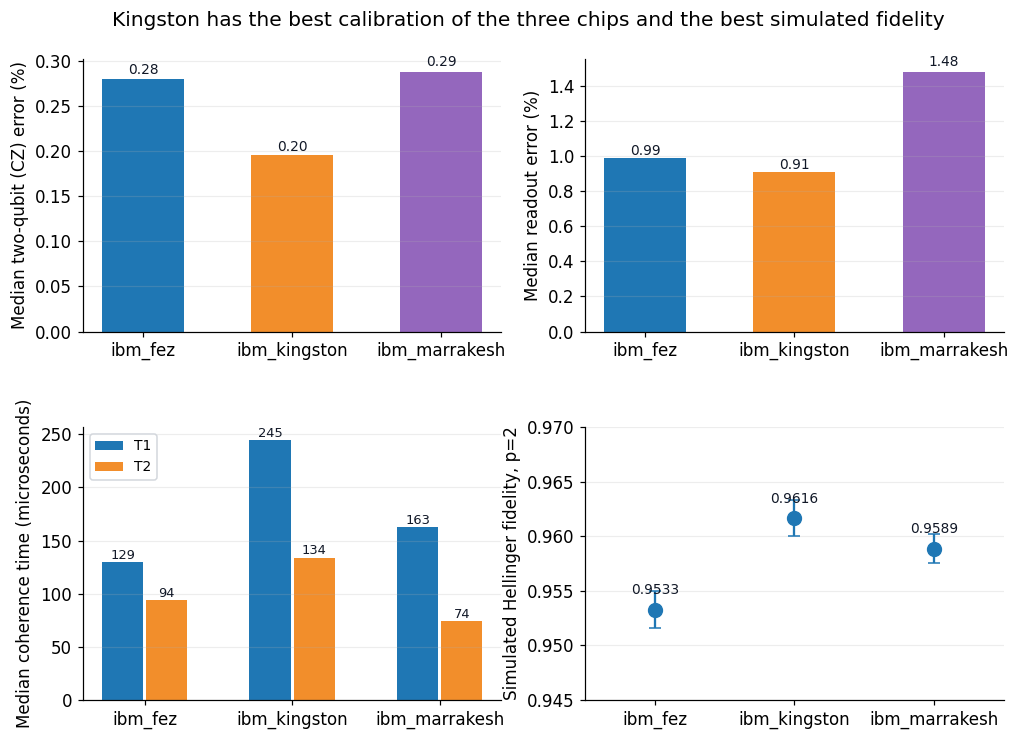

In [18]:
names = list(H5["backends"])
cal = {n: H5["backends"][n]["calibration"] for n in names}
fig, axes = plt.subplots(2, 2, figsize=(10.8, 7.2))
x = np.arange(3)
for ax, key, scale, label in ((axes[0, 0], "cz_error_median", 100, "Median two-qubit (CZ) error (%)"), (axes[0, 1], "readout_error_median", 100, "Median readout error (%)")):
    v = [scale * cal[n][key] for n in names]
    ax.bar(x, v, color=[BLUE, ORANGE, PURPLE], width=0.55)
    for xi, vi in zip(x, v):
        ax.text(xi, vi * 1.02, f"{vi:.2f}", ha="center", fontsize=9, color="#111827")
    ax.set(xticks=x, xticklabels=names, ylabel=label)
    ax.yaxis.grid(True, alpha=0.22)
for k, (key, label, color) in enumerate((("t1_us_median", "T1", BLUE), ("t2_us_median", "T2", ORANGE))):
    v = [cal[n][key] for n in names]
    axes[1, 0].bar(x + (k - 0.5) * 0.3, v, width=0.28, color=color, label=label)
    for xi, vi in zip(x + (k - 0.5) * 0.3, v):
        axes[1, 0].text(xi, vi + 3, f"{vi:.0f}", ha="center", fontsize=8.5, color="#111827")
axes[1, 0].set(xticks=x, xticklabels=names, ylabel="Median coherence time (microseconds)")
axes[1, 0].legend(loc="upper left", **LEGEND)
axes[1, 0].yaxis.grid(True, alpha=0.22)
f = [H5["backends"][n]["p"]["2"]["hellinger"]["mean"] for n in names]
e = [H5["backends"][n]["p"]["2"]["hellinger"]["std"] / np.sqrt(20) for n in names]
axes[1, 1].errorbar(x, f, yerr=e, fmt="o", color=BLUE, ms=9, capsize=4)
for xi, fi in zip(x, f):
    axes[1, 1].annotate(f"{fi:.4f}", (xi, fi), textcoords="offset points", xytext=(0, 10), ha="center", fontsize=9, color="#111827")
axes[1, 1].set(xticks=x, xticklabels=names, ylabel="Simulated Hellinger fidelity, p=2", xlim=(-0.5, 2.5), ylim=(0.945, 0.97))
axes[1, 1].yaxis.grid(True, alpha=0.22)
fig.suptitle("Kingston has the best calibration of the three chips and the best simulated fidelity")
fig.subplots_adjust(top=0.92, hspace=0.35)
plt.show()

## T7 Backend choice

In [19]:
rows = []
for n, b in H5["backends"].items():
    c = b["calibration"]
    rows.append((n, c["pending_jobs"], f"{100 * c['cz_error_median']:.2f}", f"{100 * c['readout_error_median']:.2f}", f"{c['t1_us_median']:.0f}", f"{c['t2_us_median']:.0f}",
                 f"{b['p']['1']['hellinger']['mean']:.4f}", f"{b['p']['2']['hellinger']['mean']:.4f}", f"{100 * b['p']['2']['retention']:.0f}%"))
pd.DataFrame(rows, columns=["Chip", "Queued jobs", "CZ error %", "Readout error %", "T1 us", "T2 us", "Simulated fidelity p=1", "p=2", "Share of ideal at p=2"]).style.hide(axis="index")

Chip,Queued jobs,CZ error %,Readout error %,T1 us,T2 us,Simulated fidelity p=1,p=2,Share of ideal at p=2
ibm_fez,0,0.28,0.99,129,94,0.9854,0.9533,78%
ibm_kingston,1,0.20,0.91,245,134,0.9856,0.9616,79%
ibm_marrakesh,0,0.29,1.48,163,74,0.9717,0.9589,78%


## P10 Real hardware

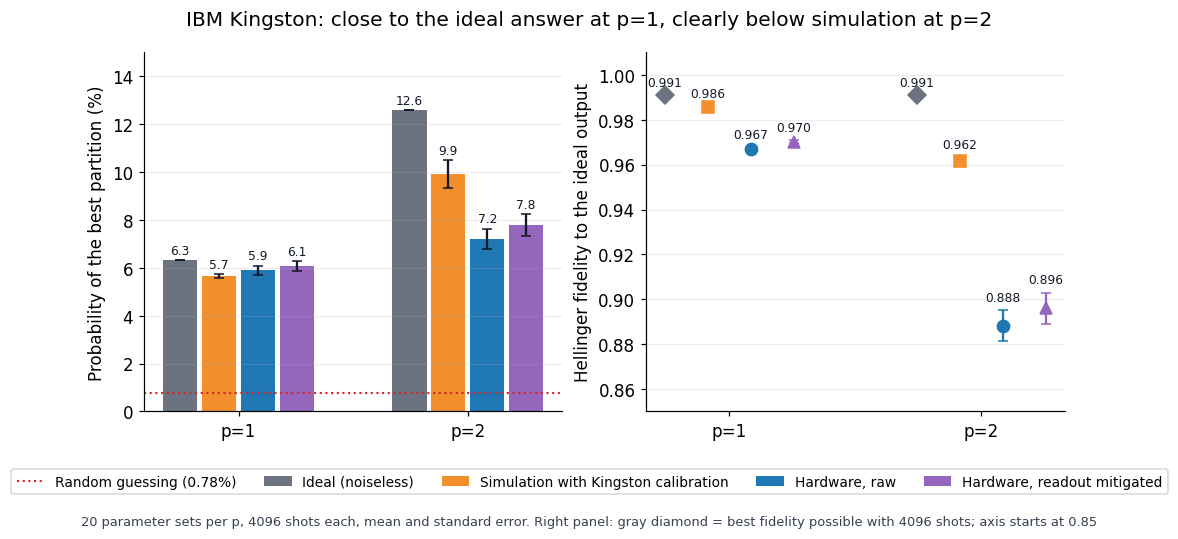

In [20]:
ps = (1, 2)
modes = [("Ideal (noiseless)", None, GRAY, "D"), ("Simulation with Kingston calibration", "same_day_simulation", ORANGE, "s"),
         ("Hardware, raw", "hardware_raw", BLUE, "o"), ("Hardware, readout mitigated", "hardware_mitigated", PURPLE, "^")]
floor = np.mean([r["summary"]["shot_floor"]["hellinger"]["mean"] for r in H4["results"]])
fig, axes = plt.subplots(1, 2, figsize=(10.8, 4.8))
for k, (name, mode, color, marker) in enumerate(modes):
    off = (k - 1.5) * 0.17
    pb, hl = [], []
    for p in ps:
        job = JOBS[("main", p)]
        if mode is None:
            pb.append((100 * np.mean([r["ideal_p_best"] for r in job["results"]]), 0))
            hl.append((floor, 0))
        else:
            v, h = 100 * hw(job, mode, "p_best"), hw(job, mode, "hellinger")
            pb.append((v.mean(), se(v)))
            hl.append((h.mean(), se(h)))
    x = [p + off for p in ps]
    axes[0].bar(x, [a for a, _ in pb], width=0.15, color=color, label=name, yerr=[b for _, b in pb], capsize=3, ecolor="#111827")
    for xi, (a, e) in zip(x, pb):
        axes[0].text(xi, a + e + 0.25, f"{a:.1f}", ha="center", fontsize=8, color="#111827")
    axes[1].errorbar(x, [a for a, _ in hl], yerr=[b for _, b in hl], fmt=marker, color=color, ms=8, capsize=3, label="Shot-noise ceiling (4096 shots)" if mode is None else name)
    for xi, (a, e) in zip(x, hl):
        axes[1].text(xi, a + e + 0.004, f"{a:.3f}", ha="center", fontsize=8, color="#111827")
axes[0].axhline(RANDOM, color=RED, ls=":", lw=1.4, label="Random guessing (0.78%)")
axes[0].set(xticks=ps, xticklabels=["p=1", "p=2"], ylabel="Probability of the best partition (%)", ylim=(0, 15))
axes[1].set(xticks=ps, xticklabels=["p=1", "p=2"], ylabel="Hellinger fidelity to the ideal output", ylim=(0.85, 1.01))
axes[0].yaxis.grid(True, alpha=0.22)
axes[1].yaxis.grid(True, alpha=0.22)
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=5, bbox_to_anchor=(0.5, 0.05), **LEGEND)
fig.suptitle("IBM Kingston: close to the ideal answer at p=1, clearly below simulation at p=2")
fig.text(0.5, 0.005, "20 parameter sets per p, 4096 shots each, mean and standard error. Right panel: gray diamond = best fidelity possible with 4096 shots; axis starts at 0.85", ha="center", fontsize=8.5, color="#374151")
fig.subplots_adjust(bottom=0.22, top=0.9)
plt.show()

## P11 Mitigation on hardware

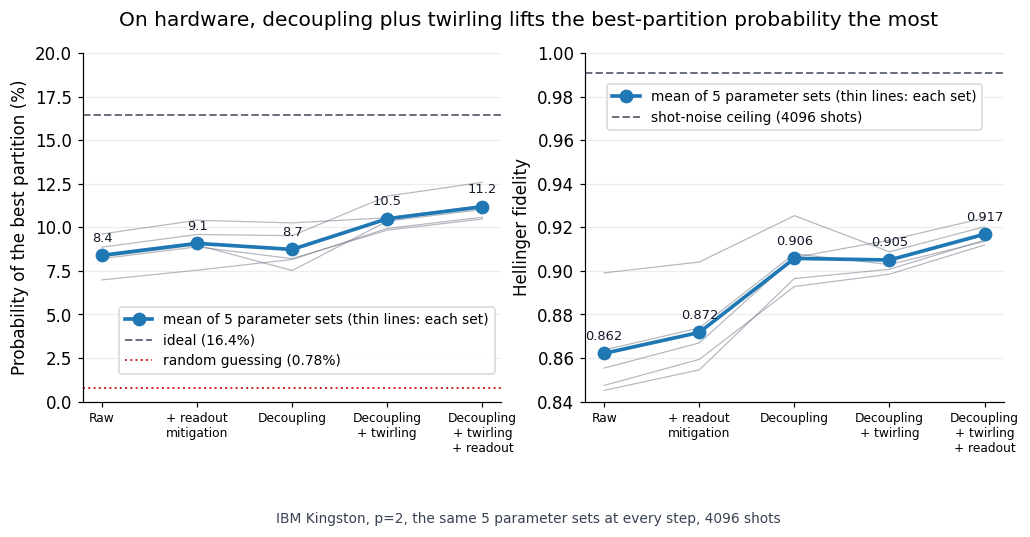

In [21]:
main, dd, ddt = JOBS[("main", 2)], JOBS[("dd", 2)], JOBS[("dd_twirl", 2)]
assert dd["seeds"] == ddt["seeds"]
idx = [main["seeds"].index(s) for s in dd["seeds"]]
steps = [("Raw", main, "hardware_raw", True), ("+ readout\nmitigation", main, "hardware_mitigated", True),
         ("Decoupling", dd, "hardware_raw", False), ("Decoupling\n+ twirling", ddt, "hardware_raw", False),
         ("Decoupling\n+ twirling\n+ readout", ddt, "hardware_mitigated", False)]
ideal = 100 * np.array([main["results"][i]["ideal_p_best"] for i in idx]).mean()
floor = np.mean([r["summary"]["shot_floor"]["hellinger"]["mean"] for r in H4["results"]])
fig, axes = plt.subplots(1, 2, figsize=(10.8, 4.8))
for ax, key, scale, label in ((axes[0], "p_best", 100, "Probability of the best partition (%)"), (axes[1], "hellinger", 1, "Hellinger fidelity")):
    vals = np.array([(hw(job, mode, key)[idx] if use else hw(job, mode, key)) * scale for _, job, mode, use in steps])
    ax.plot(range(5), vals, color=GRAY, lw=0.8, alpha=0.5)
    ax.plot(range(5), vals.mean(axis=1), color=BLUE, marker="o", ms=8, lw=2.4, label="mean of 5 parameter sets (thin lines: each set)")
    for x, m in enumerate(vals.mean(axis=1)):
        ax.annotate(f"{m:.1f}" if key == "p_best" else f"{m:.3f}", (x, m), textcoords="offset points", xytext=(0, 9), ha="center", fontsize=8.5, color="#111827")
    ax.set(xticks=range(5), xticklabels=[s[0] for s in steps], ylabel=label)
    ax.tick_params(axis="x", labelsize=8)
    ax.yaxis.grid(True, alpha=0.22)
axes[0].axhline(ideal, color=GRAY, ls="--", lw=1.3, label=f"ideal ({ideal:.1f}%)")
axes[0].axhline(RANDOM, color=RED, ls=":", lw=1.3, label="random guessing (0.78%)")
axes[0].set_ylim(0, 20)
axes[1].axhline(floor, color=GRAY, ls="--", lw=1.3, label="shot-noise ceiling (4096 shots)")
axes[1].set_ylim(0.84, 1.0)
axes[0].legend(loc="lower right", bbox_to_anchor=(1.0, 0.06), **LEGEND)
axes[1].legend(loc="upper center", bbox_to_anchor=(0.5, 0.93), **LEGEND)
fig.suptitle("On hardware, decoupling plus twirling lifts the best-partition probability the most")
fig.text(0.5, 0.01, "IBM Kingston, p=2, the same 5 parameter sets at every step, 4096 shots", ha="center", fontsize=9, color="#374151")
fig.subplots_adjust(bottom=0.24, top=0.9)
plt.show()

## P12 Hardware against simulation, per parameter set

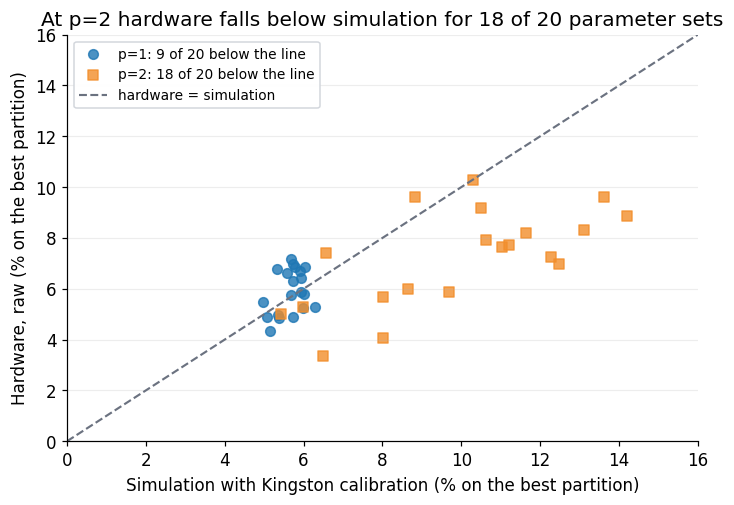

In [22]:
fig, ax = plt.subplots(figsize=(7.4, 4.8))
below = {}
for p, color, marker in ((1, BLUE, "o"), (2, ORANGE, "s")):
    job = JOBS[("main", p)]
    sim, raw = 100 * hw(job, "same_day_simulation", "p_best"), 100 * hw(job, "hardware_raw", "p_best")
    below[p] = int((raw < sim).sum())
    ax.scatter(sim, raw, color=color, marker=marker, s=40, alpha=0.8, label=f"p={p}: {below[p]} of 20 below the line")
lim = (0, 16)
ax.plot(lim, lim, color=GRAY, ls="--", lw=1.4, label="hardware = simulation")
ax.set(xlim=lim, ylim=lim, xlabel="Simulation with Kingston calibration (% on the best partition)", ylabel="Hardware, raw (% on the best partition)")
ax.yaxis.grid(True, alpha=0.22)
ax.legend(loc="upper left", **LEGEND)
ax.set_title(f"At p=2 hardware falls below simulation for {below[2]} of 20 parameter sets")
plt.show()

## P13 Output distribution, hardware against ideal

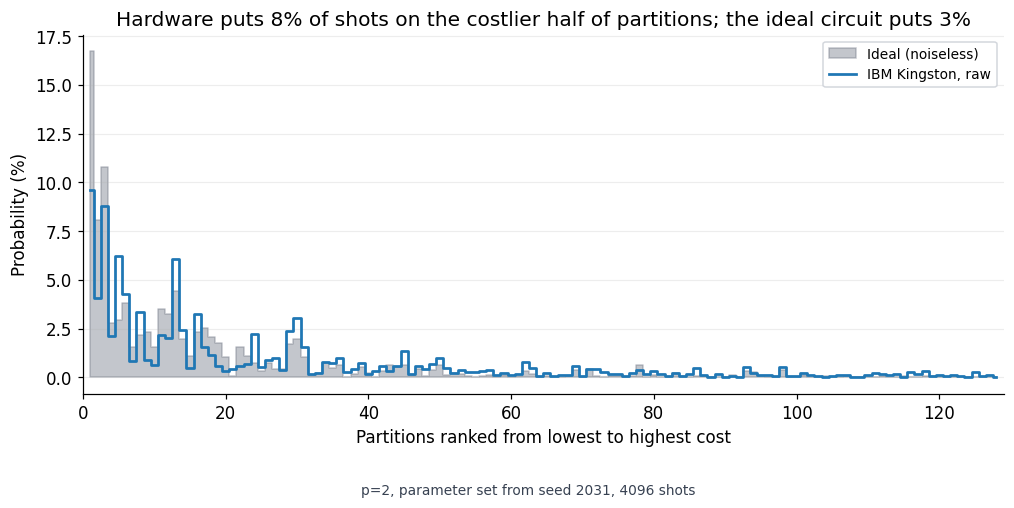

In [23]:
from qsegment import qaoa

job = JOBS[("main", 2)]
seed = 2031
k = job["seeds"].index(seed)
run = next(r for r in Q3["runs"]["2"] if r["seed"] == seed)
ideal = qaoa.ideal_probs(2, run["gammas"], run["betas"])
hard = mt.counts_to_probs(job["counts"][k], 7)
costs = np.array(sc.cost_table(2))
order = np.argsort(costs, kind="stable")
high = costs[order] > np.median(costs)
fig, ax = plt.subplots(figsize=(10.8, 4.8))
x = np.arange(1, 129)
ax.fill_between(x, 100 * ideal[order], step="mid", color=GRAY, alpha=0.4, label="Ideal (noiseless)")
ax.step(x, 100 * hard[order], where="mid", color=BLUE, lw=1.8, label="IBM Kingston, raw")
ax.set(xlabel="Partitions ranked from lowest to highest cost", ylabel="Probability (%)", xlim=(0, 129))
ax.yaxis.grid(True, alpha=0.22)
ax.legend(loc="upper right", **LEGEND)
ax.set_title(f"Hardware puts {100 * hard[order][high].sum():.0f}% of shots on the costlier half of partitions; the ideal circuit puts {100 * ideal[order][high].sum():.0f}%")
fig.text(0.5, 0.01, f"p=2, parameter set from seed {seed}, 4096 shots", ha="center", fontsize=9, color="#374151")
fig.subplots_adjust(bottom=0.2)
plt.show()

## T8 Hardware results

In [24]:
rows = []
for j in H7["jobs"]:
    res = j["results"]
    ideal = 100 * np.mean([r["ideal_p_best"] for r in res])
    for mode, label in (("same_day_simulation", "simulation"), ("hardware_raw", "hardware raw"), ("hardware_mitigated", "hardware mitigated")):
        if mode in res[0]:
            v, h = 100 * hw(j, mode, "p_best"), hw(j, mode, "hellinger")
            rows.append((j["variant"], j["p"], j["sets"], label, f"{ideal:.2f}", f"{v.mean():.2f} ± {se(v):.2f}", f"{h.mean():.4f} ± {se(h):.4f}"))
pd.DataFrame(rows, columns=["Variant", "p", "Parameter sets", "Result", "Ideal best-partition %", "Best-partition % (mean ± se)", "Hellinger fidelity (mean ± se)"]).style.hide(axis="index")

Variant,p,Parameter sets,Result,Ideal best-partition %,Best-partition % (mean ± se),Hellinger fidelity (mean ± se)
main,1,20,simulation,6.34,5.66 ± 0.08,0.9856 ± 0.0004
main,1,20,hardware raw,6.34,5.90 ± 0.19,0.9670 ± 0.0008
main,1,20,hardware mitigated,6.34,6.09 ± 0.20,0.9703 ± 0.0008
main,2,20,simulation,12.61,9.93 ± 0.59,0.9616 ± 0.0016
main,2,20,hardware raw,12.61,7.21 ± 0.43,0.8882 ± 0.0068
main,2,20,hardware mitigated,12.61,7.79 ± 0.47,0.8959 ± 0.0070
dd,2,5,hardware raw,16.44,8.73 ± 0.50,0.9057 ± 0.0057
dd,2,5,hardware mitigated,16.44,9.43 ± 0.54,0.9160 ± 0.0055
dd_twirl,2,5,hardware raw,16.44,10.49 ± 0.35,0.9050 ± 0.0028
dd_twirl,2,5,hardware mitigated,16.44,11.18 ± 0.38,0.9168 ± 0.0023


## T9 Hardware job log

In [25]:
rows = []
for j in H6["jobs"]:
    rows.append(("probe", H6["p"], f"{j['shots']} shots, 1 parameter set", j["job_id"], j["usage_seconds"], H6["backend"]))
for j in H7["jobs"]:
    rows.append((j["variant"], j["p"], f"4096 shots, {j['sets']} parameter sets", j["job_id"], j["usage_seconds"], H7["backend"]))
log = pd.DataFrame(rows, columns=["Run", "p", "Circuits", "IBM job ID", "QPU seconds", "Chip"])
print(f"Calibration used for the simulations: {H7['calibration_at_start']['calibration_time']}; QPU seconds in total: {log['QPU seconds'].sum()}; allowance left: {H7['remaining_after']} of 600 s")
log.style.hide(axis="index")

Calibration used for the simulations: 2026-10-11T13:47:00-04:00; QPU seconds in total: 77; allowance left: 523 of 600 s


Run,p,Circuits,IBM job ID,QPU seconds,Chip
probe,2,"256 shots, 1 parameter set",db5tcfcvf2bc73d0d730,2,ibm_kingston
probe,2,"1024 shots, 1 parameter set",db5tchg4qg6s73c3veig,3,ibm_kingston
main,1,"4096 shots, 20 parameter sets",db5tf4klf4us73c4hl30,26,ibm_kingston
main,2,"4096 shots, 20 parameter sets",db5tfhclf4us73c4hll0,26,ibm_kingston
dd,2,"4096 shots, 5 parameter sets",db5tfuamb58s738b090g,10,ibm_kingston
dd_twirl,2,"4096 shots, 5 parameter sets",db5tg2imb58s738b095g,10,ibm_kingston


## Results at a glance

In [26]:
q3 = Q3["summary"]
rows = [("Random guessing", f"{RANDOM:.2f}", "", "")]
for p in (1, 2, 3):
    v = [100 * r["ideal"]["p_best"] for r in Q3["runs"][str(p)]]
    rows.append((f"QAOA, noiseless, p={p} (20 sets)", f"{np.mean(v):.2f} ± {se(v):.2f}", "reference", ""))
for p in (1, 2):
    job = JOBS[("main", p)]
    ideal = 100 * np.mean([r["ideal_p_best"] for r in job["results"]])
    for label, mode in (("Simulation, Kingston calibration", "same_day_simulation"), ("Hardware, raw", "hardware_raw"), ("Hardware, readout mitigated", "hardware_mitigated")):
        v, h = 100 * hw(job, mode, "p_best"), hw(job, mode, "hellinger")
        rows.append((f"{label}, p={p} (20 sets)", f"{v.mean():.2f} ± {se(v):.2f}", f"{v.mean() / ideal:.0%}", f"{h.mean():.3f}"))
main, ddt = JOBS[("main", 2)], JOBS[("dd_twirl", 2)]
idx = [main["seeds"].index(s) for s in ddt["seeds"]]
ideal5 = 100 * np.mean([main["results"][i]["ideal_p_best"] for i in idx])
v, h = 100 * hw(ddt, "hardware_mitigated", "p_best"), hw(ddt, "hardware_mitigated", "hellinger")
rows.append(("Hardware, decoupling + twirling + readout mitigated, p=2 (5 sets)", f"{v.mean():.2f} ± {se(v):.2f}", f"{v.mean() / ideal5:.0%}", f"{h.mean():.3f}"))
table = pd.DataFrame(rows, columns=["Setting", "Best-partition probability (%, mean ± se)", "Share of ideal", "Hellinger fidelity"])
table.style.hide(axis="index").set_properties(**{"text-align": "left"})

Setting,"Best-partition probability (%, mean ± se)",Share of ideal,Hellinger fidelity
Random guessing,0.78,,
"QAOA, noiseless, p=1 (20 sets)",6.34 ± 0.05,reference,
"QAOA, noiseless, p=2 (20 sets)",12.61 ± 0.72,reference,
"QAOA, noiseless, p=3 (20 sets)",16.18 ± 1.20,reference,
"Simulation, Kingston calibration, p=1 (20 sets)",5.66 ± 0.08,89%,0.986
"Hardware, raw, p=1 (20 sets)",5.90 ± 0.19,93%,0.967
"Hardware, readout mitigated, p=1 (20 sets)",6.09 ± 0.20,96%,0.970
"Simulation, Kingston calibration, p=2 (20 sets)",9.93 ± 0.59,79%,0.962
"Hardware, raw, p=2 (20 sets)",7.21 ± 0.43,57%,0.888
"Hardware, readout mitigated, p=2 (20 sets)",7.79 ± 0.47,62%,0.896


## P14 3 zones: QAOA against random guessing

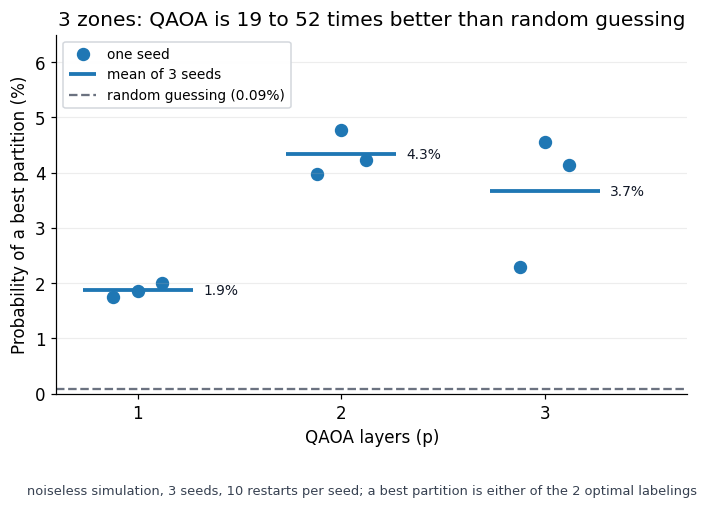

In [27]:
Q10 = json.loads((ROOT / "results" / "10_qaoa_3zone.json").read_text())
runs3 = Q10["runs"]
random3 = 100 * 2 / 3 ** 7
vals_all = [100 * r["ideal"]["p_best"] for r in runs3]
fig, ax = plt.subplots(figsize=(7.4, 4.8))
for p in (1, 2, 3):
    vals = [100 * r["ideal"]["p_best"] for r in runs3 if r["p"] == p]
    ax.scatter(p + np.array([-0.12, 0, 0.12]), vals, s=60, color=BLUE, marker="o", label="one seed" if p == 1 else None)
    ax.hlines(np.mean(vals), p - 0.27, p + 0.27, color=BLUE, lw=2.5, label="mean of 3 seeds" if p == 1 else None)
    ax.text(p + 0.32, np.mean(vals), f"{np.mean(vals):.1f}%", va="center", fontsize=9, color="#111827")
ax.axhline(random3, color=GRAY, ls="--", lw=1.5, label=f"random guessing ({random3:.2f}%)")
ax.set(xticks=[1, 2, 3], xlabel="QAOA layers (p)", ylabel="Probability of a best partition (%)", ylim=(0, 6.5), xlim=(0.6, 3.7))
ax.yaxis.grid(True, alpha=0.22)
ax.legend(loc="upper left", **LEGEND)
ax.set_title(f"3 zones: QAOA is {min(vals_all) / random3:.0f} to {max(vals_all) / random3:.0f} times better than random guessing")
fig.text(0.5, 0.01, "noiseless simulation, 3 seeds, 10 restarts per seed; a best partition is either of the 2 optimal labelings", ha="center", fontsize=8.5, color="#374151")
fig.subplots_adjust(bottom=0.2)
plt.show()

## P15 3 zones on real hardware

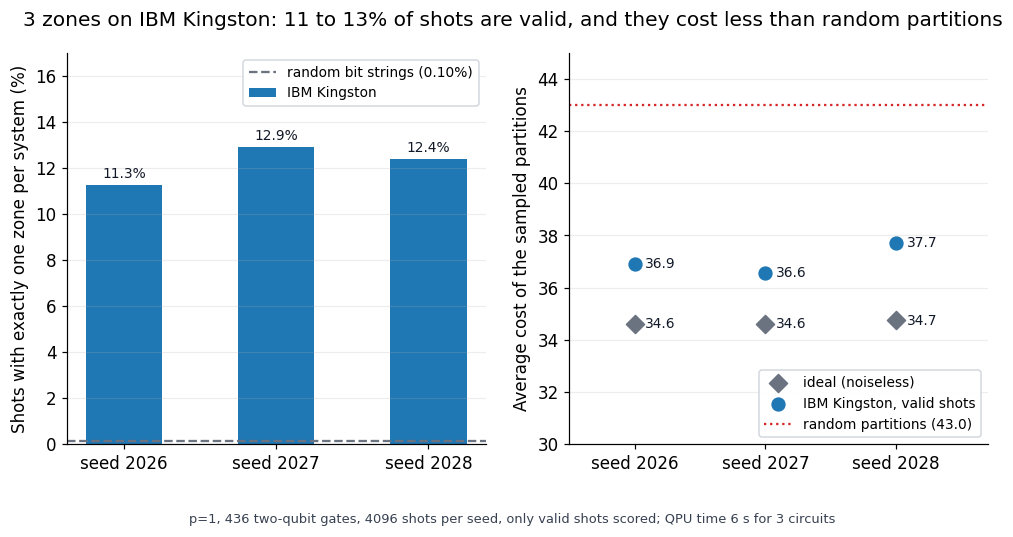

In [28]:
H12 = json.loads((ROOT / "results" / "12_hardware_3zone.json").read_text())
rows3 = H12["results"]
assert all(r["avg_cost_of_valid_shots"] < 43.0 for r in rows3)
x = np.arange(len(rows3))
labels = [f"seed {r['seed']}" for r in rows3]
valid = [100 * r["valid_share"] for r in rows3]
fig, axes = plt.subplots(1, 2, figsize=(10.8, 4.8))
axes[0].bar(x, valid, color=BLUE, width=0.5, label="IBM Kingston")
for xi, v in zip(x, valid):
    axes[0].text(xi, v + 0.3, f"{v:.1f}%", ha="center", fontsize=9, color="#111827")
axes[0].axhline(100 * H12["random_bitstring_valid_share"], color=GRAY, ls="--", lw=1.5, label=f"random bit strings ({100 * H12['random_bitstring_valid_share']:.2f}%)")
axes[0].set(xticks=x, xticklabels=labels, ylabel="Shots with exactly one zone per system (%)", ylim=(0, 17))
axes[0].legend(loc="upper right", **LEGEND)
axes[1].scatter(x, [r["ideal_avg_cost"] for r in rows3], color=GRAY, marker="D", s=70, label="ideal (noiseless)")
axes[1].scatter(x, [r["avg_cost_of_valid_shots"] for r in rows3], color=BLUE, marker="o", s=70, label="IBM Kingston, valid shots")
for xi, r in zip(x, rows3):
    axes[1].text(xi + 0.08, r["avg_cost_of_valid_shots"], f"{r['avg_cost_of_valid_shots']:.1f}", va="center", fontsize=9, color="#111827")
    axes[1].text(xi + 0.08, r["ideal_avg_cost"], f"{r['ideal_avg_cost']:.1f}", va="center", fontsize=9, color="#111827")
axes[1].axhline(43.0, color=RED, ls=":", lw=1.5, label="random partitions (43.0)")
axes[1].set(xticks=x, xticklabels=labels, ylabel="Average cost of the sampled partitions", ylim=(30, 45), xlim=(-0.5, 2.7))
axes[1].legend(loc="lower right", **LEGEND)
for ax in axes:
    ax.yaxis.grid(True, alpha=0.22)
fig.suptitle(f"3 zones on IBM Kingston: {min(valid):.0f} to {max(valid):.0f}% of shots are valid, and they cost less than random partitions")
fig.text(0.5, 0.01, f"p=1, {H12['chosen_transpile']['two_qubit_gates']} two-qubit gates, 4096 shots per seed, only valid shots scored; QPU time {H12['usage_seconds']} s for 3 circuits", ha="center", fontsize=8.5, color="#374151")
fig.subplots_adjust(bottom=0.16, top=0.9)
plt.show()

## T15 3 zones on real hardware

In [29]:
H12 = json.loads((ROOT / "results" / "12_hardware_3zone.json").read_text())
rows = []
for r in H12["results"]:
    pp_ = r["post_processing"]
    rows.append((r["seed"], f"{100 * r['valid_share']:.2f}", f"{100 * r['p_best_of_all_shots']:.3f}", f"{100 * r['p_best_of_valid_shots']:.2f}", f"{100 * r['ideal_p_best']:.2f}",
                 f"{r['avg_cost_of_valid_shots']:.1f}", f"{r['ideal_avg_cost']:.1f}", f"{pp_['success_rate']:.2f}", f"{pp_['evals_per_success']:.0f}"))
print(f"job {H12['job_id']} on {H12['backend']}, QPU {H12['usage_seconds']} s, {H12['chosen_transpile']['two_qubit_gates']} two-qubit gates, depth {H12['chosen_transpile']['depth']}; random 21-bit strings are valid {100 * H12['random_bitstring_valid_share']:.2f}% of the time")
pd.DataFrame(rows, columns=["Seed", "Valid shots (%)", "Best partition, % of all shots", "Best partition, % of valid shots", "Ideal best partition (%)", "Avg cost of valid shots", "Ideal avg cost", "Success after refinement", "Lookups per success"]).style.hide(axis="index")

job db6e7do4qg6s73c4kuv0 on ibm_kingston, QPU 6 s, 436 two-qubit gates, depth 535; random 21-bit strings are valid 0.10% of the time


Seed,Valid shots (%),"Best partition, % of all shots","Best partition, % of valid shots",Ideal best partition (%),Avg cost of valid shots,Ideal avg cost,Success after refinement,Lookups per success
2026,11.28,0.122,1.08,1.76,36.9,34.6,0.39,133
2027,12.92,0.122,0.95,1.85,36.6,34.6,0.30,167
2028,12.40,0.098,0.79,2.01,37.7,34.7,0.38,139


## T11 3 zones: classical baselines

In [30]:
B9 = json.loads((ROOT / "results" / "09_baselines_3zone.json").read_text())
rows = []
for name, label in (("random", "Random sampling"), ("greedy", "Greedy search"), ("annealing", "Simulated annealing")):
    rs = B9["runs"][name]
    rows.append((label, f"{sum(r['hit'] for r in rs)} of 3", str([r["first_hit_eval"] for r in rs]), str([round(r["first_hit_seconds"] * 1e3, 2) for r in rs])))
g = B9["gurobi"]["runs"]
rows.append(("Gurobi (exact solver)", f"optimal, {len(g)} of 3", "1 solve", str([round(r["solve_seconds"] * 1e3, 1) for r in g])))
pd.DataFrame(rows, columns=["Method (3 zones, seeds 2026-2028)", "Found a best partition", "Evaluations to first hit, per seed", "Time to first hit, ms, per seed"]).style.hide(axis="index")

"Method (3 zones, seeds 2026-2028)",Found a best partition,"Evaluations to first hit, per seed","Time to first hit, ms, per seed"
Random sampling,3 of 3,"[456, 381, 35]","[2.63, 1.69, 0.18]"
Greedy search,3 of 3,"[89, 227, 108]","[0.41, 1.04, 0.95]"
Simulated annealing,3 of 3,"[154, 38, 84]","[1.9, 0.25, 0.49]"
Gurobi (exact solver),"optimal, 3 of 3",1 solve,"[13.9, 1.3, 1.1]"


## T12 3 zones: noiseless QAOA per seed

In [31]:
Q10 = json.loads((ROOT / "results" / "10_qaoa_3zone.json").read_text())
rows = [(r["p"], r["seed"], f"{100 * r['ideal']['p_best']:.2f}", f"{r['ideal']['avg_cost']:.1f}", f"{r['tuning_seconds']:.2f}", f"{r['tuning_shots']:,}",
         f"{100 * r['qiskit_circuit_check']['valid_share']:.0f}%", f"{100 * r['qiskit_circuit_check']['p_best']:.2f}") for r in Q10["runs"]]
pd.DataFrame(rows, columns=["p", "Seed", "Best-partition probability (%)", "Average cost", "Training time (s)", "Training shots", "Valid shots in the Qiskit circuit", "Best-partition % in the Qiskit circuit"]).style.hide(axis="index")

p,Seed,Best-partition probability (%),Average cost,Training time (s),Training shots,Valid shots in the Qiskit circuit,Best-partition % in the Qiskit circuit
1,2026,1.76,34.6,0.10,"262,144",100%,1.66
1,2027,1.85,34.6,0.09,"251,904",100%,1.71
1,2028,2.01,34.7,0.07,"221,184",100%,1.98
2,2026,3.99,32.1,0.14,"323,584",100%,3.86
2,2027,4.78,31.9,0.16,"350,208",100%,5.62
2,2028,4.23,31.9,0.14,"319,488",100%,4.05
3,2026,2.30,34.3,0.23,"414,720",100%,2.32
3,2027,4.56,32.2,0.22,"393,216",100%,3.83
3,2028,4.13,32.2,0.24,"416,768",100%,4.05


## T13 3 zones: verification and gate counts

In [32]:
V8 = json.loads((ROOT / "results" / "08_verify_3zone.json").read_text())
rows = [(g["design"], g["p"], g["cx_before_routing"], g["two_qubit_gates_fake_fez"], g["depth"]) for g in V8["gate_counts"]]
print("checks passed:", sum(c["pass"] for c in V8["checks"]), "of", len(V8["checks"]), "| all pass:", V8["all_pass"])
pd.DataFrame(rows, columns=["3-zone circuit design", "p", "CX before routing", "Two-qubit gates on FakeFez (level 2, best of 3 seeds)", "Depth"]).style.hide(axis="index")

checks passed: 8 of 8 | all pass: True


3-zone circuit design,p,CX before routing,"Two-qubit gates on FakeFez (level 2, best of 3 seeds)",Depth
"W-state start, XXPlusYY mixer",1,148,445,486
"W-state start, XXPlusYY mixer",2,268,878,725
"W-state start, XXPlusYY mixer",3,388,1325,1382
"old: basis-state start, PauliEvolution mixer",1,162,376,375


## T14 Post-processing the QAOA samples

In [33]:
P11 = json.loads((ROOT / "results" / "11_postprocess_hardware.json").read_text())
Q10 = json.loads((ROOT / "results" / "10_qaoa_3zone.json").read_text())
fmt = lambda s, e: (f"{s:.2f}", f"{e:.0f}")
rows = [("2 zones", "random starts", *fmt(P11["random_starts"]["success_rate"], P11["random_starts"]["evals_per_success"]))]
for job in P11["jobs"]:
    for who, label in (("hardware", "QAOA samples from IBM Kingston"), ("ideal", "QAOA samples, noiseless")):
        rows.append((f"2 zones, p={job['p']}", label, *fmt(np.mean([r[who]["success_rate"] for r in job["rows"]]), np.mean([r[who]["evals_per_success"] for r in job["rows"]]))))
rows.append(("3 zones", "random starts", *fmt(Q10["random_starts"]["success_rate"], Q10["random_starts"]["evals_per_success"])))
for p in (1, 2, 3):
    rr = [r["post_processing"]["qaoa_exact_distribution"] for r in Q10["runs"] if r["p"] == p]
    rows.append((f"3 zones, p={p}", "QAOA samples, noiseless (3 seeds)", *fmt(np.mean([r["success_rate"] for r in rr]), np.mean([r["evals_per_success"] for r in rr]))))
pd.DataFrame(rows, columns=["Problem", "Starting partitions", "Success per start", "Cost lookups per success"]).style.hide(axis="index")

Problem,Starting partitions,Success per start,Cost lookups per success
2 zones,random starts,0.56,44
"2 zones, p=1",QAOA samples from IBM Kingston,0.58,35
"2 zones, p=1","QAOA samples, noiseless",0.58,34
"2 zones, p=2",QAOA samples from IBM Kingston,0.58,34
"2 zones, p=2","QAOA samples, noiseless",0.59,29
3 zones,random starts,0.35,177
"3 zones, p=1","QAOA samples, noiseless (3 seeds)",0.35,139
"3 zones, p=2","QAOA samples, noiseless (3 seeds)",0.35,117
"3 zones, p=3","QAOA samples, noiseless (3 seeds)",0.35,121


## T16 3 zones: where exact classical solving stalls

In [34]:
W16 = json.loads((ROOT / "results" / "16_classical_wall_3zone.json").read_text())
rows = [(r["n"], r["pairs"], r["seed"], "proved best" if r["status"] == "OPTIMAL" else "stopped at 60 s", f"{r['objective']:.0f}", f"{r['bound']:.0f}", f"{100 * r['mip_gap']:.1f}", f"{r['nodes']:.0f}") for r in W16["rows"]]
print(f"Dense random networks (half of all pairs linked), 3 zones, Gurobi on one thread, {W16['time_limit_seconds']} s limit, seeds {W16['seeds']}.")
print("Proved the best split in", sum(r["status"] == "OPTIMAL" for r in W16["rows"]), "of", len(W16["rows"]), "runs.")
pd.DataFrame(rows, columns=["Systems", "Linked pairs", "Seed", "Outcome", "Best found", "Bound", "Gap (%)", "Search nodes"])

Dense random networks (half of all pairs linked), 3 zones, Gurobi on one thread, 60 s limit, seeds [2026, 2027, 2028].
Proved the best split in 0 of 12 runs.


,Systems,Linked pairs,Seed,Outcome,Best found,Bound,Gap (%),Search nodes
0,60,885,2026,stopped at 60 s,-591,-825,39.6,597
1,60,885,2027,stopped at 60 s,-594,-952,60.3,568
2,60,885,2028,stopped at 60 s,-566,-808,42.8,618
3,80,1580,2026,stopped at 60 s,-805,-1571,95.2,145
4,80,1580,2027,stopped at 60 s,-779,-1580,102.8,162
5,80,1580,2028,stopped at 60 s,-982,-1480,50.7,58
6,100,2475,2026,stopped at 60 s,-1324,-2607,96.9,4
7,100,2475,2027,stopped at 60 s,-1222,-2515,105.8,3
8,100,2475,2028,stopped at 60 s,-1155,-2504,116.8,4
9,150,5587,2026,stopped at 60 s,-2697,-3809,41.2,23869


## T17 3 zones: error suppression and readout correction on hardware

In [35]:
S17 = json.loads((ROOT / "results" / "17_hardware_3zone_suppression.json").read_text())
names = {"plain": "plain", "dd_twirl": "decoupling + twirling"}
rows = []
for variant, res in S17["results"].items():
    for row in res["rows"]:
        for mode, label in (("raw", "raw"), ("readout_mitigated", "+ readout correction")):
            m = row[mode]
            rows.append((names[variant], label, row["seed"], f"{100 * m['valid_share']:.1f}", f"{100 * m['p_best_of_valid_shots']:.2f}", f"{100 * row['ideal_p_best']:.2f}",
                         f"{m['avg_cost_of_valid_shots']:.1f}", f"{m['hellinger_valid_vs_ideal']:.2f}", f"{m['post_processing']['mean_final_cost']:.1f}"))
for variant, res in S17["results"].items():
    print(f"{names[variant]}: job {S17['job_ids'][variant]}, {res['job']['usage_seconds']} s on {S17['backend']}, median readout error {100 * res['readout_flip_median']:.2f}%")
pd.DataFrame(rows, columns=["Chip run", "Readouts", "Seed", "Valid (%)", "Best split, of valid (%)", "Ideal best (%)", "Avg cost of valid", "Hellinger to ideal", "Cost after post-processing"])

plain: job db7cqjiraffc73fa926g, 8 s on ibm_kingston, median readout error 1.22%
decoupling + twirling: job db7cqjmil99s73fnr8sg, 8 s on ibm_kingston, median readout error 1.43%


,Chip run,Readouts,Seed,Valid (%),"Best split, of valid (%)",Ideal best (%),Avg cost of valid,Hellinger to ideal,Cost after post-processing
0,plain,raw,2026,13.2,2.41,1.76,36.7,0.36,26.4
1,plain,+ readout correction,2026,14.0,2.81,1.76,36.3,0.36,26.4
2,plain,raw,2027,12.0,0.61,1.85,36.9,0.32,26.5
3,plain,+ readout correction,2027,12.7,0.58,1.85,36.7,0.32,26.5
4,plain,raw,2028,12.8,0.57,2.01,37.0,0.37,26.4
5,plain,+ readout correction,2028,13.5,0.62,2.01,36.8,0.37,26.5
6,decoupling + twirling,raw,2026,1.5,1.59,1.76,38.0,0.04,26.4
7,decoupling + twirling,+ readout correction,2026,1.5,1.57,1.76,38.0,0.04,26.4
8,decoupling + twirling,raw,2027,1.3,0.00,1.85,38.2,0.04,26.6
9,decoupling + twirling,+ readout correction,2027,1.3,0.00,1.85,38.2,0.04,26.6
